# Stage 2 — Gap-Coverage Atlas

**The single most important diagnostic in the whole project.** It decides whether daily forecasting is physically possible in this region, or whether we have to drop the target to a 3-day rolling composite.

## Why this comes before any modelling
Winter convective blooms in the Malta–Sicily Channel happen *in exactly the cloudiest season*. If you only discover that coverage is poor after training models, you'll have wasted weeks. Front-load the pain here.

## What we measure
For each day, the **valid-pixel fraction** = (non-NaN pixels) / (total pixels). Average those daily fractions per month → a 12-bar climatology. Then read the winter bars.

## The decision branch
- **Dec–Feb mean coverage ≥ 25%** → proceed with **daily** forecasting as planned.
- **Dec–Feb mean coverage < 25%** → switch the target to a **3-day rolling composite** for the rest of the pipeline. Note the decision in your lab log — it is a legitimate, defensible methodological choice, not a compromise.

## 2.1 — Load the cube from Stage 1

Reuse the file we produced in `01-Data-Acquisition.ipynb`. We don't recompute or re-download anything here.

In [1]:
from pathlib import Path
import xarray as xr

RAW_DIR  = Path("data/raw")
FIG_DIR  = Path("figs")
PROC_DIR = Path("data/processed")
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

CHL_PATH = RAW_DIR / "chl_malta_2021_2023.nc"
assert CHL_PATH.exists(), f"Missing {CHL_PATH} — run 01-Data-Acquisition first."

ds  = xr.open_dataset(CHL_PATH, chunks={"time": 50})
chl = ds.CHL
print(f"Loaded: {dict(chl.sizes)}")
print(f"Time  : {str(chl.time.values.min())[:10]} → {str(chl.time.values.max())[:10]}")

Loaded: {'time': 1095, 'latitude': 198, 'longitude': 272}
Time  : 2021-01-01 → 2023-12-31


## 2.2 — Daily valid-pixel fraction

Sum the non-NaN mask across (lat, lon) per day, divide by the spatial pixel count. This reduction *is* dask-safe (sum-along-axis works fine), so we don't pay the load cost from Stage 1's median trick.

In [2]:
import pandas as pd

spatial_dims = ["latitude", "longitude"]
n_pixels = chl.isel(time=0).size

valid_per_day = chl.notnull().sum(dim=spatial_dims) / n_pixels
valid_per_day = valid_per_day.compute()                # small (~1095 floats)
valid_per_day = valid_per_day.to_series().rename("valid_frac")

print(f"Daily coverage — min {valid_per_day.min()*100:5.1f}%  "
      f"median {valid_per_day.median()*100:5.1f}%  "
      f"max {valid_per_day.max()*100:5.1f}%")
valid_per_day.describe().round(3)

Daily coverage — min   0.0%  median  56.2%  max  84.9%


count    1095.000
mean        0.486
std         0.308
min         0.000
25%         0.177
50%         0.562
75%         0.786
max         0.849
Name: valid_frac, dtype: float64

## 2.3 — Monthly climatology of coverage

Average the daily fractions by calendar month to get a 12-value seasonal cycle.

In [3]:
monthly = valid_per_day.groupby(valid_per_day.index.month).mean()
monthly.index.name = "month"
monthly_pct = (monthly * 100).round(1).rename("coverage_%")
print("Mean daily valid-pixel fraction by month (%):")
print(monthly_pct)

monthly_pct.to_csv(PROC_DIR / "coverage_monthly.csv")
valid_per_day.to_frame().to_parquet(PROC_DIR / "coverage_daily.parquet")

Mean daily valid-pixel fraction by month (%):
month
1     40.7
2     49.4
3     47.3
4     42.0
5     46.2
6     47.3
7     63.5
8     62.1
9     46.6
10    53.5
11    44.2
12    40.3
Name: coverage_%, dtype: float64


## 2.4 — Plot it

Bar chart of monthly mean coverage, with the 25% decision threshold drawn in red.

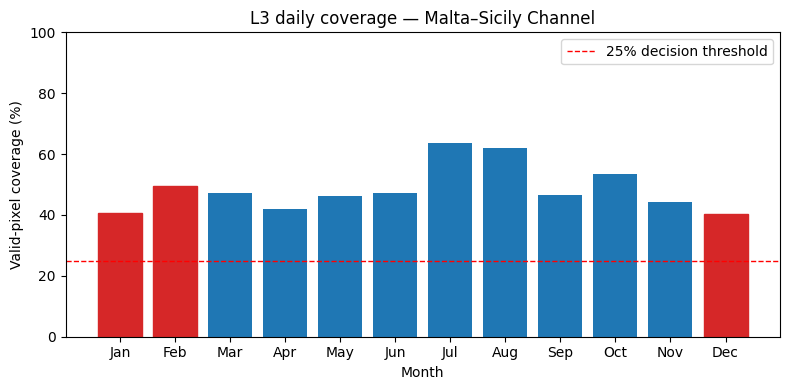

Saved → figs\02_coverage_atlas.png


In [4]:
import matplotlib.pyplot as plt

MONTH_LABELS = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(MONTH_LABELS, monthly_pct.values,
              color=["#1f77b4"]*12)
for i in (11, 0, 1):                # Dec, Jan, Feb — highlight winter
    bars[i].set_color("#d62728")
ax.axhline(25, color="red", linestyle="--", linewidth=1, label="25% decision threshold")
ax.set_ylabel("Valid-pixel coverage (%)")
ax.set_xlabel("Month")
ax.set_title("L3 daily coverage — Malta–Sicily Channel")
ax.set_ylim(0, 100)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_coverage_atlas.png", dpi=150)
plt.show()
print(f"Saved → {FIG_DIR / '02_coverage_atlas.png'}")

---
## Validation Gate 2 — the decision branch

The cell below computes **Dec-Jan-Feb mean coverage** and prints the methodological recommendation. Record the number and the decision in your lab log.

In [5]:
winter_months = [12, 1, 2]
winter_cov = monthly.loc[winter_months].mean()
print(f"Winter (DJF) mean valid-pixel coverage: {winter_cov*100:.1f}%\n")

if winter_cov >= 0.25:
    decision = "DAILY"
    print("DECISION: DAILY target.")
    print("  Coverage in the worst season clears the 25% bar — daily L3 forecasting is viable.")
    print("  Build the supervised dataset (Stage 4) with the raw daily CHL as target.")
else:
    decision = "3-DAY COMPOSITE"
    print("DECISION: 3-DAY ROLLING COMPOSITE target.")
    print("  Winter coverage is below 25% — single-day targets will be too gappy to learn from.")
    print("  In Stage 4, build the target as:")
    print('      chl_target = chl.rolling(time=3, min_periods=1).mean()')
    print("  Predictors stay daily; only the *target* is composited.")

# persist the decision so later notebooks can read it
with open(PROC_DIR / "coverage_decision.txt", "w") as f:
    f.write(f"{decision}\nwinter_djf_coverage_pct={winter_cov*100:.2f}\n")
print(f"\nDecision written to {PROC_DIR / 'coverage_decision.txt'}")

Winter (DJF) mean valid-pixel coverage: 43.5%

DECISION: DAILY target.
  Coverage in the worst season clears the 25% bar — daily L3 forecasting is viable.
  Build the supervised dataset (Stage 4) with the raw daily CHL as target.

Decision written to data\processed\coverage_decision.txt


### Gate 2 checklist
- [ ] `figs/02_coverage_atlas.png` exists and is readable.
- [ ] Winter (DJF) coverage number is **written down** somewhere durable (lab log, README).
- [ ] You've branched: either **daily** or **3-day composite**. `data/processed/coverage_decision.txt` records it.
- [ ] You're not surprised by summer being high-coverage and winter being low — that's the whole shape of the problem.

## 2.5 — Bonus: pixel-wise coverage map (optional)

Per-pixel fraction of valid days, averaged over the whole record. Useful for spotting persistently cloud-shadowed strips or coastal-mask edge effects.

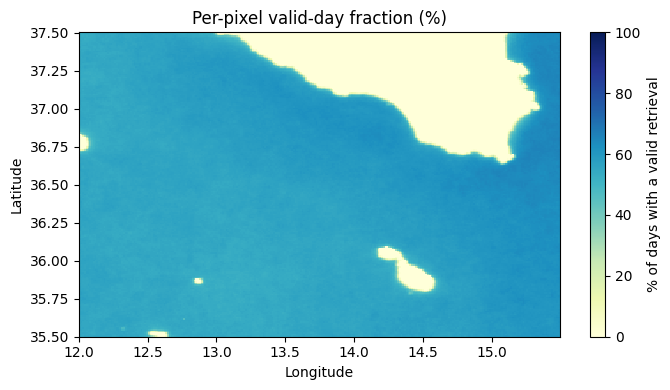

In [6]:
import matplotlib.pyplot as plt

pix_valid = chl.notnull().mean(dim="time").compute()    # lat × lon, 0..1

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(pix_valid.longitude, pix_valid.latitude,
                   pix_valid * 100, shading="auto",
                   cmap="YlGnBu", vmin=0, vmax=100)
ax.set_title("Per-pixel valid-day fraction (%)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.colorbar(im, ax=ax, label="% of days with a valid retrieval")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_coverage_map.png", dpi=150)
plt.show()

---
## Next: `03-Covariates.ipynb`

Pulls L3 SST and bathymetry for the same box & period — the minimal predictor set to get the pipeline running end-to-end. The full covariate stack (wind, waves, salinity, currents, MLD, optics) lands later in Stage 8.